In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


In [3]:
df= pd.read_csv(path+"/bs140513_032310.csv")

In [4]:
df.head()

,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [5]:
df['category'].value_counts()

,count
category,
'es_transportation',505119
'es_food',26254
'es_health',16133
'es_wellnessandbeauty',15086
'es_fashion',6454
'es_barsandrestaurants',6373
'es_hyper',6098
'es_sportsandtoys',4002
'es_tech',2370


## Data Description
  - Step: This feature represents the day from the start of simulation. It has 180 steps so simulation ran for virtually 6 months.
  - Customer: This feature represents the customer id
  - zipCodeOrigin: The zip code of origin/source.
  - Merchant: The merchant's id
  - zipMerchant: The merchant's zip code
  - Age: Categorized age
    * 0: <= 18,
    * 1: 19-25,
    * 2: 26-35,
    * 3: 36-45,
    * 4: 46:55,
    * 5: 56:65,
    * 6: > 65
    * U: Unknown
  - Gender: Gender for customer
    - E : Enterprise,
    - F: Female,
    - M: Male,
    - U: Unknown
  - Category: Category of the purchase.
    - es_transportation
    - es_food
    - es_health
    - es_wellnessandbeauty
    - es_fashion
    - es_barsandrestaurants
    - es_hyper
    - es_sportsandtoys
    - es_tech
    - es_home
    - es_hotelservices
    - es_otherservices
    - es_contents
    - es_travel
    - es_leisure
  - Amount: Amount of the purchase
  - Fraud: Target variable which shows if the transaction fraudulent(1) or benign(0)


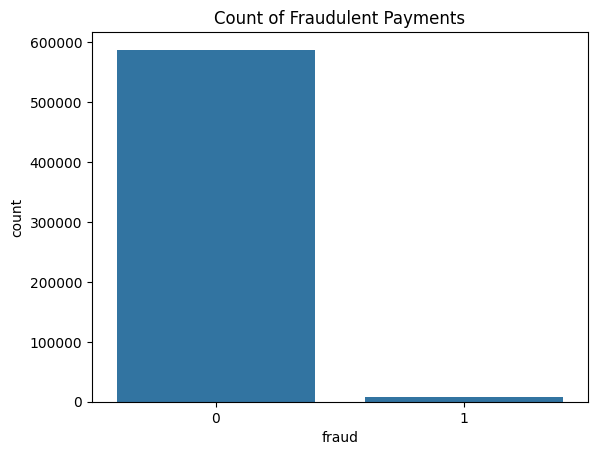

No of Fraudulent Transactions :  7200
No of Non Fraudulent Transactions :  587443


In [6]:
df_fraud=df.loc[df.fraud==1]
df_non_fraud=df.loc[df.fraud==0]
sns.countplot(x="fraud",data=df)
plt.title('Count of Fraudulent Payments')
plt.show()
print("No of Fraudulent Transactions : ",df_fraud.fraud.count())
print("No of Non Fraudulent Transactions : ",df_non_fraud.fraud.count())

In [7]:
print('Mean feature value per category',df.groupby('category')[['amount','fraud']].mean() )

Mean feature value per category                               amount     fraud
category                                      
'es_barsandrestaurants'    43.461014  0.018829
'es_contents'              44.547571  0.000000
'es_fashion'               65.666642  0.017973
'es_food'                  37.070405  0.000000
'es_health'               135.621367  0.105126
'es_home'                 165.670846  0.152064
'es_hotelservices'        205.614249  0.314220
'es_hyper'                 45.970421  0.045917
'es_leisure'              288.911303  0.949900
'es_otherservices'        135.881524  0.250000
'es_sportsandtoys'        215.715280  0.495252
'es_tech'                 120.947937  0.066667
'es_transportation'        26.958187  0.000000
'es_travel'              2250.409190  0.793956
'es_wellnessandbeauty'     65.511221  0.047594


In [8]:
pd.concat([df_fraud.groupby('category')['amount'].mean(),
           df_non_fraud.groupby('category')['amount'].mean(),
           df.groupby('category')['fraud'].mean()*100],
           keys=["fraudulent","non-fraudulent", "percent%"], axis=1, sort=False).sort_values(by=['non-fraudulent'])

,fraudulent,non-fraudulent,percent%
category,,,
'es_transportation',NaN,26.958187,0.000000
'es_food',NaN,37.070405,0.000000
'es_hyper',169.255429,40.037145,4.591669
'es_barsandrestaurants',164.092667,41.145997,1.882944
'es_contents',NaN,44.547571,0.000000
'es_wellnessandbeauty',229.422535,57.320219,4.759380
'es_fashion',247.008190,62.347674,1.797335
'es_leisure',300.286878,73.230400,94.989980
'es_otherservices',316.469605,75.685497,25.000000


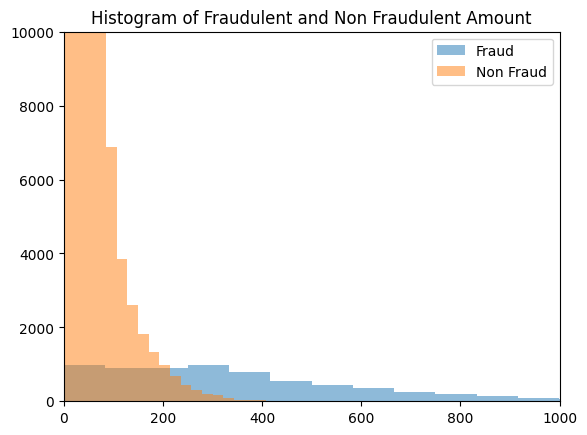

In [9]:
plt.hist(df_fraud.amount,alpha=0.5,label="Fraud",bins=100)
plt.hist(df_non_fraud.amount,alpha=0.5,label="Non Fraud",bins=100)
plt.title('Histogram of Fraudulent and Non Fraudulent Amount')
plt.xlim(0,1000)
plt.ylim(0,10000)
plt.legend()
plt.show()

In [10]:
print((df.groupby('age')['fraud'].mean()*100).reset_index().rename(columns={'age':'Age','fraud':'Fraud Percent'}).sort_values(by='Fraud Percent'))

   Age  Fraud Percent
7  'U'       0.594228
6  '6'       0.974826
5  '5'       1.095112
1  '1'       1.185254
3  '3'       1.192815
2  '2'       1.251401
4  '4'       1.293281
0  '0'       1.957586


In [11]:
print('No of Unique zipCodeOri: ',df.zipcodeOri.nunique())
print('No of Unique zipMerchant: ',df.zipMerchant.nunique())


No of Unique zipCodeOri:  1
No of Unique zipMerchant:  1


In [12]:
data_reduced=df.drop(['zipcodeOri','zipMerchant'],axis=1)

In [13]:
data_reduced.columns

Index(['step', 'customer', 'age', 'gender', 'merchant', 'category', 'amount',
       'fraud'],
      dtype='object')

In [14]:
data_reduced.select_dtypes(['object']).columns

Index(['customer', 'age', 'gender', 'merchant', 'category'], dtype='object')

In [15]:
cols_categorical=data_reduced.select_dtypes(include=['object']).columns
for col in cols_categorical:
  data_reduced[col]=data_reduced[col].astype('category')
data_reduced[cols_categorical]=data_reduced[cols_categorical].apply(lambda x: x.cat.codes)
data_reduced.head(5)

,step,customer,age,gender,merchant,category,amount,fraud
0,0,210,4,2,30,12,4.55,0
1,0,2753,2,2,30,12,39.68,0
2,0,2285,4,1,18,12,26.89,0
3,0,1650,3,2,30,12,17.25,0
4,0,3585,5,2,30,12,35.72,0


In [16]:
data_reduced.loc[:,['customer','merchant','category']].astype('category')
data_reduced.loc[:,['customer','merchant','category','gender']] = pd.get_dummies(data_reduced.loc[:,['customer','merchant','category','gender']],drop_first=True)

In [17]:
col_categorical = data_reduced.select_dtypes(include= ['object']).columns
for col in col_categorical:
    data_reduced[col] = data_reduced[col].astype('category')
# categorical values ==> numeric values
data_reduced[col_categorical] = data_reduced[col_categorical].apply(lambda x: x.cat.codes)
data_reduced.head(5)

,step,customer,age,gender,merchant,category,amount,fraud
0,0,210,4,2,30,12,4.55,0
1,0,2753,2,2,30,12,39.68,0
2,0,2285,4,1,18,12,26.89,0
3,0,1650,3,2,30,12,17.25,0
4,0,3585,5,2,30,12,35.72,0


In [20]:
X=data_reduced.drop(['fraud'],axis=1)
y=df['fraud']
print(X.head(),"\n")
print(y.head())

   step  customer  age  gender  merchant  category  amount
0     0       210    4       2        30        12    4.55
1     0      2753    2       2        30        12   39.68
2     0      2285    4       1        18        12   26.89
3     0      1650    3       2        30        12   17.25
4     0      3585    5       2        30        12   35.72 

0    0
1    0
2    0
3    0
4    0
Name: fraud, dtype: int64


In [24]:
y[y==1].value_counts()

,count
fraud,
1,7200


In [26]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
X_res,y_res=smote.fit_resample(X,y)
y_res=pd.DataFrame(y_res)
print(y_res['fraud'].value_counts())

fraud
0    587443
1    587443
Name: count, dtype: int64


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X_res,y_res,test_size=0.3,random_state=42,shuffle=True,stratify=y_res)

In [30]:
def plot_roc_auc(y_test, preds):
  fpr, tpr, threshold=roc_curve(y_test,preds)
  roc_auc=auc(fpr,tpr)
  plt.title('Receiver Operating Characteristic')
  plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
  plt.legend(loc = 'lower right')
  plt.plot([0, 1], [0, 1],'r--')
  plt.xlim([0, 1])
  plt.ylim([0, 1])
  plt.ylabel('True Positive Rate')
  plt.xlabel('False Positive Rate')
  plt.show()

In [31]:
import xgboost as xgb
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
import numpy as np

In [32]:
print("Base accuracy score we must beat is: ",
      df_non_fraud.fraud.count()/ np.add(df_non_fraud.fraud.count(),df_fraud.fraud.count()) * 100)

Base accuracy score we must beat is:  98.7891894800746


Classification Report for K-Nearest Neighbours: 
               precision    recall  f1-score   support

           0       1.00      0.98      0.99    176233
           1       0.98      1.00      0.99    176233

    accuracy                           0.99    352466
   macro avg       0.99      0.99      0.99    352466
weighted avg       0.99      0.99      0.99    352466

Confusion Matrix of K-Nearest Neigbours: 
 [[171999   4234]
 [   362 175871]]


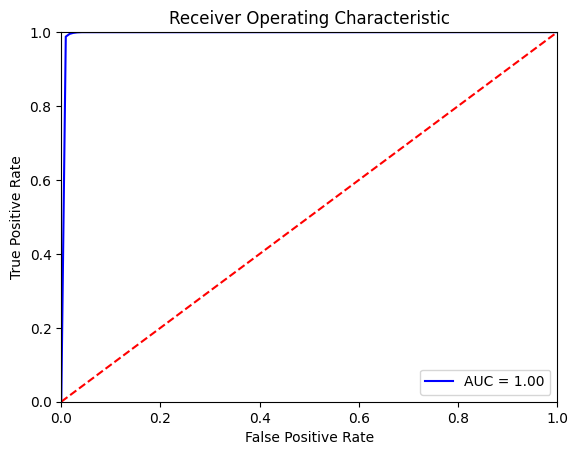

In [33]:
knn = KNeighborsClassifier(n_neighbors=5,p=1)

knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)


print("Classification Report for K-Nearest Neighbours: \n", classification_report(y_test, y_pred))
print("Confusion Matrix of K-Nearest Neigbours: \n", confusion_matrix(y_test,y_pred))
plot_roc_auc(y_test, knn.predict_proba(X_test)[:,1])

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   53.7s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:  1.7min finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    1.4s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    2.6s finished


Classification Report for Random Forest Classifier: 
               precision    recall  f1-score   support

           0       0.99      0.97      0.98    176233
           1       0.97      0.99      0.98    176233

    accuracy                           0.98    352466
   macro avg       0.98      0.98      0.98    352466
weighted avg       0.98      0.98      0.98    352466

Confusion Matrix of Random Forest Classifier: 
 [[170106   6127]
 [  1079 175154]]


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    1.1s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    2.2s finished


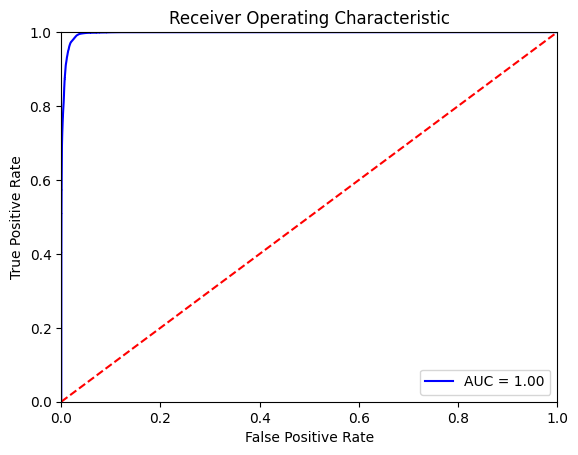

In [34]:
rf_clf = RandomForestClassifier(n_estimators=100,max_depth=8,random_state=42,
                                verbose=1,class_weight="balanced")

rf_clf.fit(X_train,y_train)
y_pred = rf_clf.predict(X_test)

print("Classification Report for Random Forest Classifier: \n", classification_report(y_test, y_pred))
print("Confusion Matrix of Random Forest Classifier: \n", confusion_matrix(y_test,y_pred))
plot_roc_auc(y_test, rf_clf.predict_proba(X_test)[:,1])

Classification Report for XGBoost: 
               precision    recall  f1-score   support

           0       1.00      0.99      0.99    176233
           1       0.99      1.00      0.99    176233

    accuracy                           0.99    352466
   macro avg       0.99      0.99      0.99    352466
weighted avg       0.99      0.99      0.99    352466

Confusion Matrix of XGBoost: 
 [[174100   2133]
 [   787 175446]]


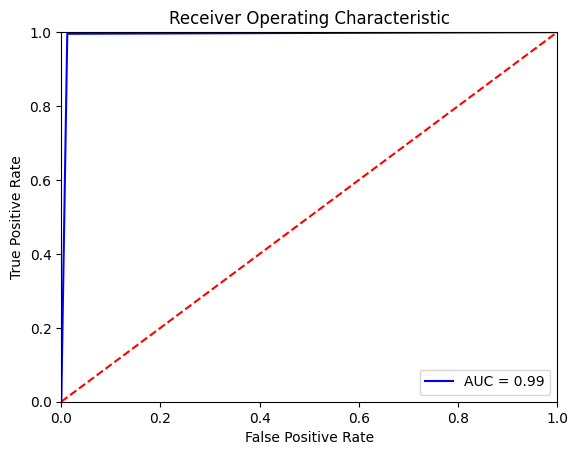

In [36]:
XGBoost_CLF = xgb.XGBClassifier(max_depth=6, learning_rate=0.05, n_estimators=400,
                                objective="binary:hinge", booster='gbtree',
                                n_jobs=-1, nthread=None, gamma=0, min_child_weight=1, max_delta_step=0,
                                subsample=1, colsample_bytree=1, colsample_bylevel=1, reg_alpha=0, reg_lambda=1,
                                scale_pos_weight=1, base_score=0.5, random_state=42, verbosity=1)

XGBoost_CLF.fit(X_train,y_train)

y_pred = XGBoost_CLF.predict(X_test)

print("Classification Report for XGBoost: \n", classification_report(y_test, y_pred))
print("Confusion Matrix of XGBoost: \n", confusion_matrix(y_test,y_pred))
plot_roc_auc(y_test, XGBoost_CLF.predict_proba(X_test)[:,1])